# Proyek Analisis Data: [bike-sharing-analysis]
- **Nama:** [Nabila Wahyu Khairunnisa]
- **Email:** [nabilakhairunnisa098@gmail.com/ds350b6x1945@student.devacademy.id]
- **ID Dicoding:** [ds350b6x1945]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada setiap musim selama periode 2011–2012, dan musim mana yang tingkat permintaannya tertinggi atau terendah?
- **Pertanyaan 2:** Bagaimana pola rata-rata jumlah penyewaan sepeda pada setiap jam selama periode 2011–2012, dan perbedaan antara hari kerja dan hari non-kerja berdasarkan jenis pengguna casual dan registered?


## Import Semua Packages/Library yang Digunakan

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid", palette="Set2")
# Mengatur format tampilan angka
pd.set_option('display.float_format', '{:,.2f}'.format)

## Data Wrangling

### Gathering Data

#### Load df ...

In [34]:
day_df = pd.read_csv("day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


In [35]:
# Melihat ukuran dataset
print("Ukuran day_df:", day_df.shape)

Ukuran day_df: (731, 16)


In [36]:
hour_df = pd.read_csv("hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


In [37]:
# Melihat ukuran dataset
print("Ukuran day_df:", hour_df.shape)

Ukuran day_df: (17379, 17)


**Insight:** (Opsional)
- Dataset day.csv memiliki 731 baris dan 16 kolom, data penyewaan harian
- Dataset hour.csv memiliki 17.379 baris dan 17 kolom, data penyewaan per jam
- Dataset harian digunakan untuk menganalisis polapenyewaan berdasarkan musim, sedangkan dataset per jam digunakan untuk menganalisis pola waktu dan jenis pengguna

### Assessing Data

#### Identifying ... problem

In [38]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [39]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.50,6.52,0.03,3.00,0.68,1.40,0.50,0.47,0.63,0.19,848.18,"3,656.17","4,504.35"
std,211.17,1.11,0.50,3.45,0.17,2.00,0.47,0.54,0.18,0.16,0.14,0.08,686.62,"1,560.26","1,937.21"
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.00,4.00,0.00,1.00,0.00,1.00,0.34,0.34,0.52,0.13,315.50,"2,497.00","3,152.00"
50%,366.00,3.00,1.00,7.00,0.00,3.00,1.00,1.00,0.50,0.49,0.63,0.18,713.00,"3,662.00","4,548.00"
75%,548.50,3.00,1.00,10.00,0.00,5.00,1.00,2.00,0.66,0.61,0.73,0.23,"1,096.00","4,776.50","5,956.00"
max,731.00,4.00,1.00,12.00,1.00,6.00,1.00,3.00,0.86,0.84,0.97,0.51,"3,410.00","6,946.00","8,714.00"


In [40]:
print("cek jumlah data duplikat",hour_df.duplicated().sum())
print("cek jumlah data kosong",hour_df.isnull().sum())

cek jumlah data duplikat 0
cek jumlah data kosong instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [41]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [42]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,"17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00"
mean,"8,690.00",2.50,0.50,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
std,"5,017.03",1.11,0.50,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,"4,345.50",2.00,0.00,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,"8,690.00",3.00,1.00,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,"13,034.50",3.00,1.00,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,"17,379.00",4.00,1.00,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00


In [43]:
print("cek jumlah data duplikat",day_df.duplicated().sum())
print("cek jumlah data kosong",day_df.isnull().sum())

cek jumlah data duplikat 0
cek jumlah data kosong instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [44]:
#memeriksa nilai unik pada kolom kategori
categorical_columns = [
    'season', 'yr', 'mnth', 'weekday',
    'workingday', 'weathersit'
]
for col in categorical_columns:
    #konversi setiap nilai unik ke tipe data int standar Python
    unique_vals = [int(x) for x in day_df[col].dropna().unique()]
    print(f"Nilai unik {col}: {sorted(unique_vals)}")

for col in categorical_columns:
    unique_vals = [int(x) for x in hour_df[col].dropna().unique()]
    print(f"Nilai unik {col} pada hour_df: {sorted(unique_vals)}")

#rentang jam
hr_vals = [int(x) for x in hour_df['hr'].dropna().unique()]
print(f"Rentang jam: {sorted(hr_vals)}")

Nilai unik season: [1, 2, 3, 4]
Nilai unik yr: [0, 1]
Nilai unik mnth: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Nilai unik weekday: [0, 1, 2, 3, 4, 5, 6]
Nilai unik workingday: [0, 1]
Nilai unik weathersit: [1, 2, 3]
Nilai unik season pada hour_df: [1, 2, 3, 4]
Nilai unik yr pada hour_df: [0, 1]
Nilai unik mnth pada hour_df: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Nilai unik weekday pada hour_df: [0, 1, 2, 3, 4, 5, 6]
Nilai unik workingday pada hour_df: [0, 1]
Nilai unik weathersit pada hour_df: [1, 2, 3, 4]
Rentang jam: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


In [45]:
#memeriksa kesesuaian total penyewaan dengan jumlah pengguna
day_mismatch = (
    day_df['cnt'] != day_df['casual'] + day_df['registered']
).sum()

hour_mismatch = (
    hour_df['cnt'] != hour_df['casual'] + hour_df['registered']
).sum()

print("Ketidaksesuaian total day_df:", day_mismatch)
print("Ketidaksesuaian total hour_df:", hour_mismatch)

Ketidaksesuaian total day_df: 0
Ketidaksesuaian total hour_df: 0


**Steps to Take:**
- Mengubah kolom dteday menjadi tipe datetime agar dapat digunakan dalam analisis berbasis waktu.
- Memeriksa kolom kategorikal yang masih direpresentasikan dengan angka dan mempertimbangkan konversi tipe datanya.
- Memastikan tidak terdapat duplikasi pada catatan data.
- Memeriksa konsistensi kolom cnt dengan penjumlahan casual dan registered.
- Memeriksa nilai di luar rentang yang diperbolehkan pada variabel kategorikal dan numerik.

**Insight:** (Opsional)
- Kedua dataset sudah bersih tidak ada missing value maupun duplikat data

### Cleaning Data

#### Fixing ... problem

In [46]:
#mengubah tipe data kolom 'dteday' jadi 'daytime'
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
day_df.info()
print("\n")
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [47]:
#mengubah kode musim jadi label
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

day_df['season_label'] = day_df['season'].map(season_mapping)
day_df.head()
hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16,Spring
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40,Spring
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32,Spring
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13,Spring
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1,Spring


In [48]:
#meengubah workingday jadi label
workingday_mapping = {
    0: 'Non-Working Day',
    1: 'Working Day'
}

day_df['workingday_label'] = day_df['workingday'].map(
    workingday_mapping
)
print(day_df.head())
print("\n\n\n\n")
hour_df['workingday_label'] = hour_df['workingday'].map(
    workingday_mapping
)
print(hour_df.head())

   instant     dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1 2011-01-01       1   0     1        0        6           0   
1        2 2011-01-02       1   0     1        0        0           0   
2        3 2011-01-03       1   0     1        0        1           1   
3        4 2011-01-04       1   0     1        0        2           1   
4        5 2011-01-05       1   0     1        0        3           1   

   weathersit  temp  atemp  hum  windspeed  casual  registered   cnt  \
0           2  0.34   0.36 0.81       0.16     331         654   985   
1           2  0.36   0.35 0.70       0.25     131         670   801   
2           1  0.20   0.19 0.44       0.25     120        1229  1349   
3           1  0.20   0.21 0.59       0.16     108        1454  1562   
4           1  0.23   0.23 0.44       0.19      82        1518  1600   

  season_label workingday_label  
0       Spring  Non-Working Day  
1       Spring  Non-Working Day  
2       Spring      Workin

In [49]:
#ubah kolom kategorikal menjadi category
category_columns = [
    'season', 'yr', 'mnth', 'weekday',
    'workingday', 'weathersit'
]

for col in category_columns:
    day_df[col] = day_df[col].astype('category')
    hour_df[col] = hour_df[col].astype('category')

In [50]:
print("Tipe data day_df:")
display(day_df.dtypes)
print("\n")
print("Tipe data hour_df:")
display(hour_df.dtypes)

Tipe data day_df:


,0
instant,int64
dteday,datetime64[ns]
season,category
yr,category
mnth,category
holiday,int64
weekday,category
workingday,category
weathersit,category
temp,float64




Tipe data hour_df:


,0
instant,int64
dteday,datetime64[ns]
season,category
yr,category
mnth,category
hr,int64
holiday,int64
weekday,category
workingday,category
weathersit,category


**Insight:** (Opsional)
- Kolom tanggal sudah dikonversi jadi datetime, digunakan untuk olahan data berbasis waktu
- Kode musim dan jenis hari sudah dilengkapi dengan label jadi lebih mudah dipahami

## Exploratory Data Analysis (EDA)

### Explore ...

In [51]:
hour_df.sample(10)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,workingday_label
3903,3904,2011-06-16,2,0,6,13,0,4,1,2,0.72,0.67,0.54,0.25,37,114,151,Summer,Working Day
13298,13299,2012-07-13,3,1,7,7,0,5,1,2,0.70,0.65,0.54,0.00,27,353,380,Fall,Working Day
16029,16030,2012-11-05,4,1,11,14,0,1,1,1,0.38,0.39,0.40,0.16,31,165,196,Winter,Working Day
16744,16745,2012-12-05,4,1,12,11,0,3,1,1,0.44,0.44,0.44,0.28,11,161,172,Winter,Working Day
14772,14773,2012-09-12,3,1,9,17,0,3,1,1,0.70,0.64,0.41,0.30,114,811,925,Fall,Working Day
2659,2660,2011-04-25,2,0,4,17,0,1,1,1,0.70,0.65,0.54,0.30,80,441,521,Summer,Working Day
16733,16734,2012-12-05,4,1,12,0,0,3,1,1,0.50,0.48,0.59,0.28,6,31,37,Winter,Working Day
11304,11305,2012-04-21,2,1,4,5,0,6,0,1,0.50,0.48,0.82,0.25,0,1,1,Summer,Non-Working Day
5158,5159,2011-08-07,3,0,8,20,0,0,0,1,0.72,0.71,0.84,0.13,50,133,183,Fall,Non-Working Day
6015,6016,2011-09-13,3,0,9,5,0,2,1,1,0.56,0.53,0.88,0.00,1,19,20,Fall,Working Day


In [52]:
#rata-rata penyewaan berdasarkan musim
season_analysis = (
    day_df.groupby('season_label', observed=True)
    .agg(
        average_rentals=('cnt', 'mean'),
        total_rentals=('cnt', 'sum'),
        total_days=('cnt', 'count')
    )
    .reset_index()
    .sort_values('average_rentals', ascending=False)
)

display(season_analysis)

,season_label,average_rentals,total_rentals,total_days
0,Fall,"5,644.30",1061129,188
2,Summer,"4,992.33",918589,184
3,Winter,"4,728.16",841613,178
1,Spring,"2,604.13",471348,181


In [53]:
#rata-rata penyewaan berdasarkan musim (2011-2012)
year_season_analysis = (
    day_df.groupby(['yr', 'season_label'], observed=True)
    ['cnt']
    .mean()
    .reset_index(name='average_rentals')
)

display(year_season_analysis)

,yr,season_label,average_rentals
0,0,Fall,"4,464.36"
1,0,Spring,"1,666.67"
2,0,Summer,"3,775.17"
3,0,Winter,"3,664.46"
4,1,Fall,"6,824.24"
5,1,Spring,"3,531.30"
6,1,Summer,"6,209.49"
7,1,Winter,"5,791.87"


In [54]:
#rata-rata penyewaan per jam berdasarkan jenis hari
hour_analysis = (
    hour_df.groupby(
        ['hr', 'workingday_label'],
        observed=True
    )
    .agg(
        average_casual=('casual', 'mean'),
        average_registered=('registered', 'mean'),
        average_rentals=('cnt', 'mean')
    )
    .reset_index()
)

display(hour_analysis.head(10))

,hr,workingday_label,average_casual,average_registered,average_rentals
0,0,Non-Working Day,16.65,74.15,90.80
1,0,Working Day,7.15,29.64,36.79
2,1,Non-Working Day,12.50,57.00,69.51
3,1,Working Day,3.71,12.84,16.55
4,2,Non-Working Day,10.40,42.77,53.17
5,2,Working Day,2.14,6.55,8.68
6,3,Non-Working Day,6.45,19.32,25.78
7,3,Working Day,0.91,4.03,4.94
8,4,Non-Working Day,2.26,6.00,8.26
9,4,Working Day,0.77,4.66,5.43


In [55]:
#rata-rata penyewaan tertinggi berdasarkan jam
peak_hours = (
    hour_analysis
    .sort_values('average_rentals', ascending=False)
    .groupby('workingday_label')
    .head(3)
)

display(peak_hours)

,hr,workingday_label,average_casual,average_registered,average_rentals
35,17,Working Day,56.90,468.39,525.29
37,18,Working Day,50.45,441.78,492.23
17,8,Working Day,22.26,454.74,477.01
26,13,Non-Working Day,136.42,236.31,372.73
24,12,Non-Working Day,126.25,240.01,366.26
28,14,Non-Working Day,139.59,225.05,364.65


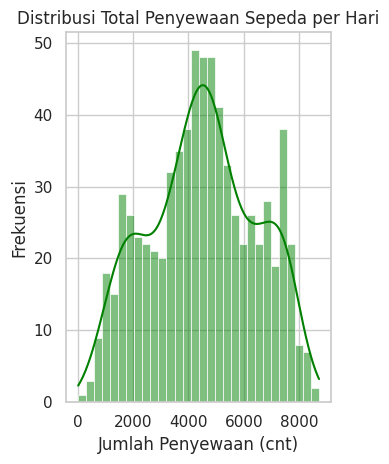

In [56]:
#distribusi Total Penyewaan Sepeda per Hari
plt.subplot(1, 2, 2)
sns.histplot(day_df['cnt'], kde=True, color='green', bins=30)
plt.title('Distribusi Total Penyewaan Sepeda per Hari')
plt.xlabel('Jumlah Penyewaan (cnt)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

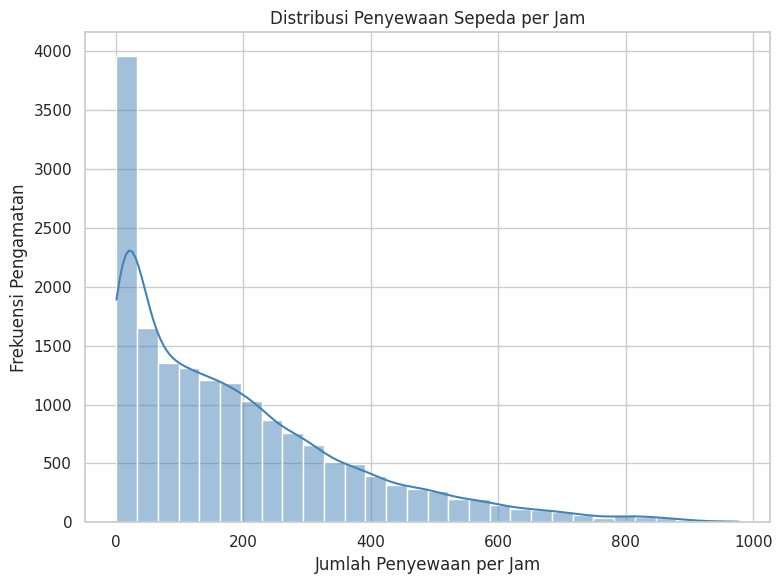

In [57]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 1, figsize=(8, 6))

#distribusi penyewaan sepeda per jam
sns.histplot(
    data=hour_df,
    x='cnt',
    kde=True,
    bins=30,
    color='steelblue',
    ax=axes
)
axes.set_title('Distribusi Penyewaan Sepeda per Jam')
axes.set_xlabel('Jumlah Penyewaan per Jam')
axes.set_ylabel('Frekuensi Pengamatan')

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pada jam berapa rata-rata penyewaan tertinggi terjadi pada hari kerja?

Pada (Working Day), rata-rata penyewaan tertinggi terjadi pada Jam 17.00 (hr 17) dengan rata-rata mencapai 525.29 penyewaan
- Pada jam berapa rata-rata penyewaan tertinggi terjadi pada hari non-kerja?

Pada hari libur/non-kerja (Non-Working Day), rata-rata penyewaan tertinggi terjadi pada Jam 13.00 (hr 13) dengan rata-rata sebesar 372.73 penyewaan
- Jenis pengguna mana yang lebih dominan pada masing-masing jenis hari?

Jenis pengguna registered (terdaftar/langganan) jauh lebih dominan secara konsisten pada kedua jenis hari (baik hari kerja maupun hari libur) dibandingkan pengguna casual.
- Apakah pola penggunaan casual dan registered menunjukkan perbedaan?

Pengguna Registered: Memiliki kurva dua puncak (double peaks) yang sangat tajam pada hari kerja, yakni di pagi hari (jam 08.00) dan sore hari (jam 17.00–18.00)

Pengguna Casual: Memiliki pola yang lebih landai dan terkonsentrasi di tengah hari (pukul 12.00–14.00), yang mencerminkan karakteristik pengguna untuk tujuan rekreasi atau wisata santai

## Visualization & Explanatory Analysis

### Pertanyaan 1: Analisis Rata-rata Penyewaan Sepeda Berdasarkan Musim Selama Tahun 2011–2012

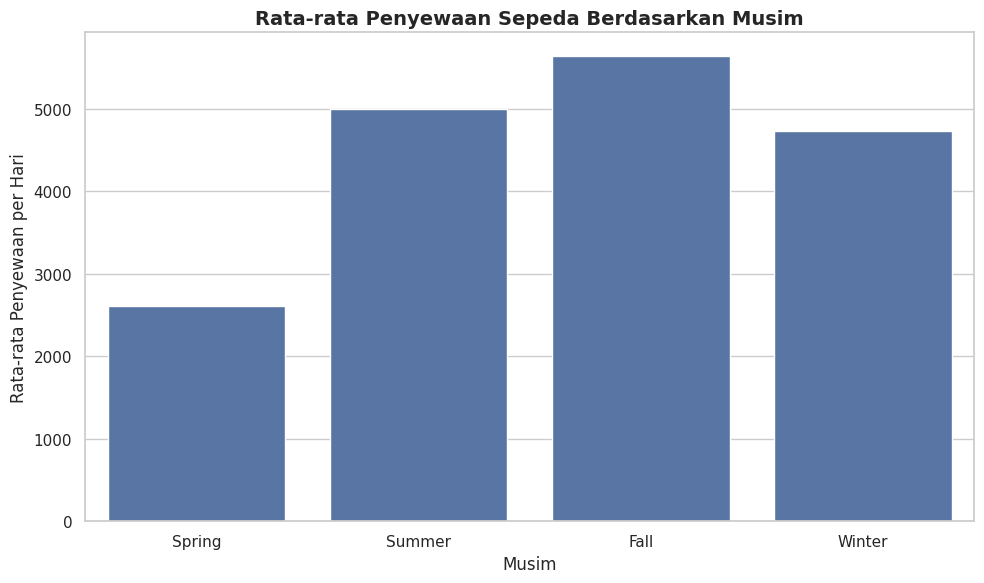

In [58]:
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=season_analysis,
    x='season_label',
    y='average_rentals',
    order=season_order
)

plt.title(
    'Rata-rata Penyewaan Sepeda Berdasarkan Musim',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Musim')
plt.ylabel('Rata-rata Penyewaan per Hari')
plt.tight_layout()
plt.show()

### Pertanyaan 2: Analisis Pola Rata-rata Penyewaan Sepeda Berdasarkan Jam pada Hari Kerja dan Hari Non-Kerja

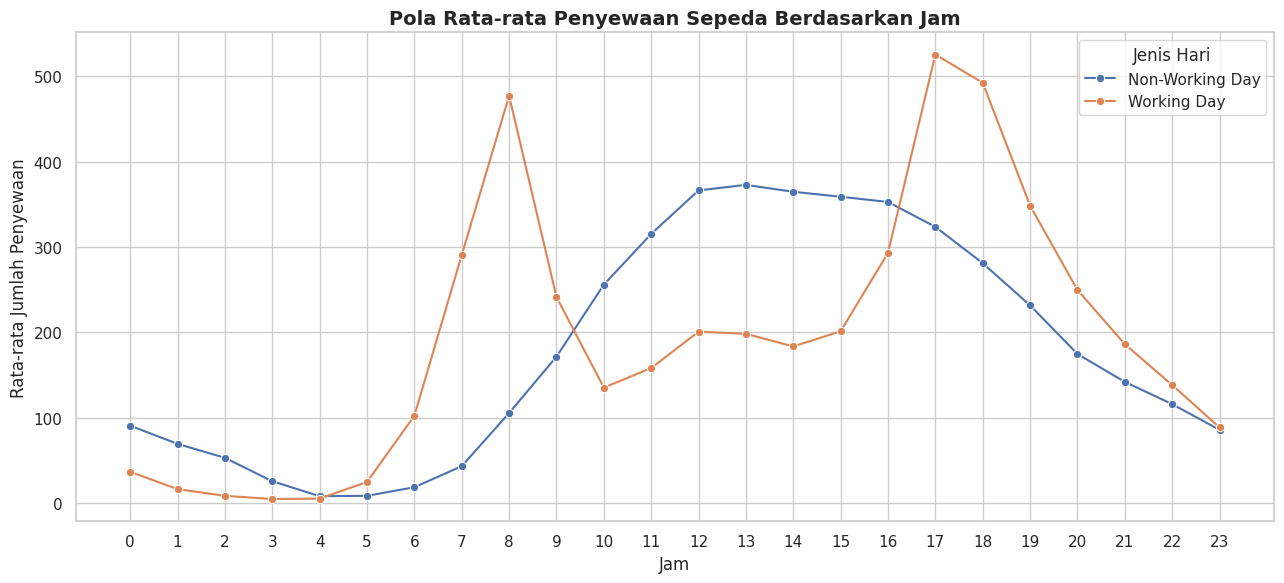

In [59]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=hour_analysis,
    x='hr',
    y='average_rentals',
    hue='workingday_label',
    marker='o',
    errorbar=None
)

plt.title(
    'Pola Rata-rata Penyewaan Sepeda Berdasarkan Jam',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.legend(title='Jenis Hari')
plt.tight_layout()
plt.show()

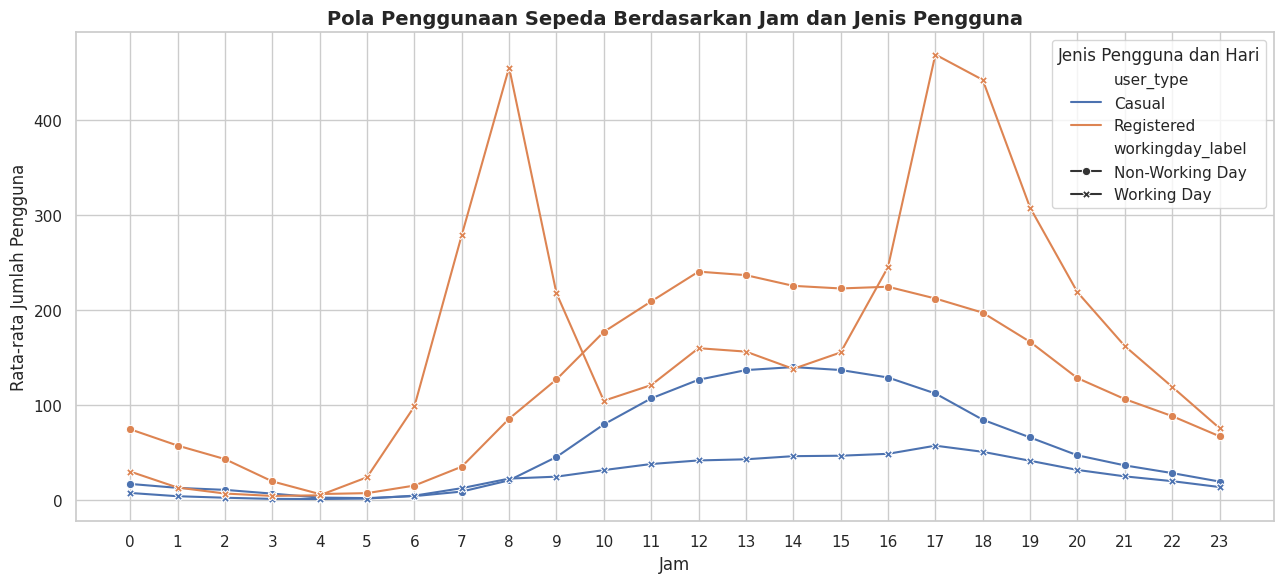

In [60]:
user_hour_analysis = hour_analysis.melt(
    id_vars=['hr', 'workingday_label'],
    value_vars=['average_casual', 'average_registered'],
    var_name='user_type',
    value_name='average_users'
)

user_hour_analysis['user_type'] = (
    user_hour_analysis['user_type']
    .map({
        'average_casual': 'Casual',
        'average_registered': 'Registered'
    })
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=user_hour_analysis,
    x='hr',
    y='average_users',
    hue='user_type',
    style='workingday_label',
    markers=True,
    dashes=False,
    errorbar=None
)

plt.title(
    'Pola Penggunaan Sepeda Berdasarkan Jam dan Jenis Pengguna',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Pengguna')
plt.xticks(range(24))
plt.legend(title='Jenis Pengguna dan Hari')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Berdasarkan visualisasi, rata-rata penyewaan sepeda tertinggi ditemukan pada musim gugur  dengan rata rata penyewaan mencapai lebih dari 5.500 penyewaan perhari, sedangkan yang terendah ditemukan pada musim semi dengan penyewaan kisaran 2.600 penyewaan perhari
- Pada hari kerja, pola penyewaan menunjukkan memiliki dua puncak tajam, yaitu pada Jam 08.00 pagi sekitar 480 penyewaan saat jam berangkat kerja/sekolah, dan puncak tertingginya pada Jam 17.00 sore mencapai lebih dari 520 penyewaan saat jam pulang kerja.
- Pada hari non-kerja, pola penyewaan menunjukkan memiliki pola kurva yang lebih landai dan terkonsentrasi di siang hari, dengan puncak penyewaan terjadi pada pukul 12.00 hingga 14.00 siang sekitar 370 penyewaan, mencerminkan aktivitas rekreasi atau jalan-jalan santai
- Pengguna registered terlihat lebih mendominasi dibandingkan pengguna casual

## Analisis Lanjutan (Opsional)

In [61]:
#membagi jumlah penyewaan ke dalam tiga kategori
day_df['demand_category'] = pd.qcut(
    day_df['cnt'],
    q=3,
    labels=['Low Demand', 'Medium Demand', 'High Demand']
)

#menghitung distribusi kategori permintaan berdasarkan musim
demand_by_season = pd.crosstab(
    day_df['season_label'],
    day_df['demand_category'],
    normalize='index'
) * 100

display(demand_by_season.round(2))

demand_category,Low Demand,Medium Demand,High Demand
season_label,,,
Fall,6.91,42.02,51.06
Spring,77.35,18.23,4.42
Summer,20.11,38.59,41.30
Winter,30.34,34.27,35.39


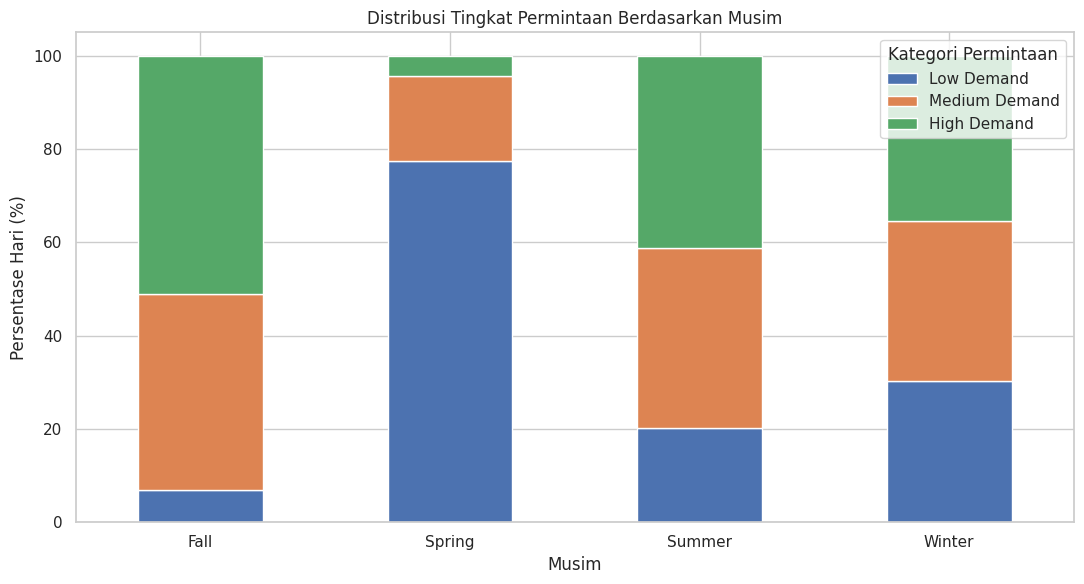

In [62]:
demand_by_season.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Distribusi Tingkat Permintaan Berdasarkan Musim')
plt.xlabel('Musim')
plt.ylabel('Persentase Hari (%)')
plt.legend(title='Kategori Permintaan')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [63]:
#mengambil data harian
daily_data = day_df[
    ['dteday', 'cnt', 'casual', 'registered']
].copy()

#ganti nama kolom agar tidak tertukar
daily_data = daily_data.rename(columns={
    'cnt': 'daily_cnt',
    'casual': 'daily_casual',
    'registered': 'daily_registered'
})

#enggabungkan data per jam di informasi harian
main_data = pd.merge(
    hour_df,
    daily_data,
    on='dteday',
    how='left',
    validate='many_to_one'
)

#hasil penggabungan
print("Ukuran data:", main_data.shape)
print("Jumlah data kosong:")
print(main_data.isnull().sum())

# 6. Menyimpan hasil ke CSV
main_data.to_csv('main_data.csv', index=False)

print("main_data.csv berhasil dibuat!")


Ukuran data: (17379, 22)
Jumlah data kosong:
instant             0
dteday              0
season              0
yr                  0
mnth                0
hr                  0
holiday             0
weekday             0
workingday          0
weathersit          0
temp                0
atemp               0
hum                 0
windspeed           0
casual              0
registered          0
cnt                 0
season_label        0
workingday_label    0
daily_cnt           0
daily_casual        0
daily_registered    0
dtype: int64
main_data.csv berhasil dibuat!


In [64]:
print("Tipe data day_df:")
display(day_df.dtypes)
print("\n")
print("Tipe data hour_df:")
display(hour_df.dtypes)

Tipe data day_df:


,0
instant,int64
dteday,datetime64[ns]
season,category
yr,category
mnth,category
holiday,int64
weekday,category
workingday,category
weathersit,category
temp,float64




Tipe data hour_df:


,0
instant,int64
dteday,datetime64[ns]
season,category
yr,category
mnth,category
hr,int64
holiday,int64
weekday,category
workingday,category
weathersit,category


**Insight:** (Opsional)
- Kategori permintaan High Demand memiliki proporsi terbesar pada musim fall
- Musim Fall memiliki distribusi kategori High Demand yang lebih tinggi dibandingkan musim lainnya
- Pengelompokan ini memberikan gambaran tambahan mengenai distribusi tingkat permintaan harian pada setiap musim.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, rata-rata penyewaan sepeda tertinggi terjadi pada musim Fall (Gugur), dengan rata-rata 5,644.30 penyewaan per hari. Sementara itu, musim Spring (Semi) memiliki rata-rata terendah, yaitu 2,604.13 penyewaan per hari.
- **Conclusion pertanyaan 2:** Berdasarkan analisis per jam, pola penyewaan pada hari kerja menunjukkan dua puncak (double peaks) yang tajam pada jam berangkat (08.00 pagi) dan jam pulang kerja/sekolah (17.00–18.00 sore), sedangkan pada hari non-kerja menunjukkan pola yang landai dan terkonsentrasi di siang hari (pukul 12.00–14.00). Pengguna Registered (terdaftar) memiliki rata-rata penyewaan lebih tinggi pada kedua jenis hari, mendominasi mobilitas komuter maupun rekreasi dibandingkan pengguna casual.
- Hasil binning menunjukkan bahwa distribusi tingkat permintaan berbeda pada setiap musim. Kategori High Demand memiliki proporsi terbesar pada musim Fall

**Rekomendasi Action Item:**
- Pengelola dapat mempertimbangkan penyesuaian ketersediaan armada berdasarkan musim dengan permintaan relatif tinggi dan rendah (fokus menambah ketersediaan armada secara maksimal saat musim Fall dan Summer, serta melakukan perawatan armada saat musim Spring).
- Pengelola dapat mengevaluasi kebutuhan distribusi sepeda pada jam-jam dengan rata-rata permintaan tinggi, terutama dengan mempertimbangkan perbedaan karakteristik pengguna pada hari kerja dan non-kerja (menyiapkan stok sepeda lebih banyak di stasiun kawasan perkantoran/komuter pada pagi dan sore hari kerja, serta di area rekreasi/taman saat siang hari di akhir pekan).